In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

df = pd.read_csv('/kaggle/input/datasets/ahmadlmomani/bank-marketing-dataset/bank.csv')

print("Dataset Shape:", df.shape)

df.head()


Dataset Shape: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [3]:

print("Dataset Information:")
df.info()

print("\nDataset Description:")
display(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB

Dataset Description:


,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000



Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']


In [4]:

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print("Number of duplicates:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["deposit"].value_counts())

print("\nTarget Percentages:")
print(df["deposit"].value_counts(normalize=True) * 100)


Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

Duplicate Rows:
Number of duplicates: 0

Target Distribution:
deposit
no     5873
yes    5289
Name: count, dtype: int64

Target Percentages:
deposit
no     52.616019
yes    47.383981
Name: proportion, dtype: float64


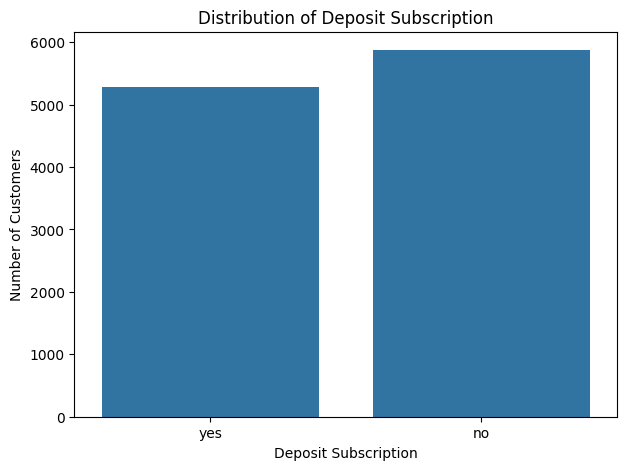

In [5]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="deposit")

plt.title("Distribution of Deposit Subscription")
plt.xlabel("Deposit Subscription")
plt.ylabel("Number of Customers")

plt.show()


In [6]:

# Separate Features and Target

X = df.drop(columns=["deposit", "duration"])

y = df["deposit"].map({
    "yes": 1,
    "no": 0
})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Classes:")
print(y.value_counts())


Features Shape: (11162, 15)
Target Shape: (11162,)

Target Classes:
deposit
0    5873
1    5289
Name: count, dtype: int64


In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (8929, 15)
Testing Features: (2233, 15)
Training Target: (8929,)
Testing Target: (2233,)


In [8]:

# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

# Create preprocessing pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         categorical_features)
    ]
)

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing Completed!")
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)


Numerical Features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Preprocessing Completed!
Processed Training Shape: (8929, 50)
Processed Testing Shape: (2233, 50)


In [9]:

import os
import shutil

output_dir = "/kaggle/working/processed_data"

os.makedirs(output_dir, exist_ok=True)

feature_names = preprocessor.get_feature_names_out()

X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)

X_test_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

X_train_df.to_csv(f"{output_dir}/X_train.csv", index=False)
X_test_df.to_csv(f"{output_dir}/X_test.csv", index=False)

y_train.to_csv(f"{output_dir}/y_train.csv", index=False)
y_test.to_csv(f"{output_dir}/y_test.csv", index=False)

# Create ZIP file
shutil.make_archive(
    "/kaggle/working/processed_data",
    "zip",
    output_dir
)

print("All files saved successfully!")

print(os.listdir(output_dir))


All files saved successfully!
['X_train.csv', 'y_train.csv', 'y_test.csv', 'X_test.csv']
